In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

import os

# Find CSV files attached to the notebook

for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        if file.endswith('.csv'):
            print(os.path.join(root, file))


/kaggle/input/datasets/spscientist/students-performance-in-exams/StudentsPerformance.csv


In [3]:

# Load the dataset

import glob

csv_files = glob.glob('/kaggle/input/**/*.csv', recursive=True)

df = pd.read_csv(csv_files[0])

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [4]:

df.head()


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [5]:

# Check dataset dimensions

print("Rows and Columns:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns)

# Check data types
print("\nDataset Information:")
df.info()


Rows and Columns: (1000, 8)

Column Names:
Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [6]:

# Display dataset information

print("Dataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [7]:

# Check missing values

print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [8]:

# Check duplicate records

print("Total duplicate rows:", df.duplicated().sum())


Total duplicate rows: 0


In [9]:

# Statistical summary

df.describe()


,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [10]:

# Average scores

print("Average Maths Score:", df['math score'].mean())

print("Average Reading Score:", df['reading score'].mean())

print("Average Writing Score:", df['writing score'].mean())


Average Maths Score: 66.089
Average Reading Score: 69.169
Average Writing Score: 68.054


In [11]:

# Gender-wise performance analysis

gender_analysis = df.groupby('gender')[
    ['math score', 'reading score', 'writing score']
].mean()

print(gender_analysis)


        math score  reading score  writing score
gender                                          
female   63.633205      72.608108      72.467181
male     68.728216      65.473029      63.311203


In [12]:

# Hypothesis testing through average comparison

reading_comparison = df.groupby('gender')['reading score'].mean()

print(reading_comparison)

if reading_comparison['female'] > reading_comparison['male']:
    print("Hypothesis supported by the data.")
else:
    print("Hypothesis not supported by the data.")


gender
female    72.608108
male      65.473029
Name: reading score, dtype: float64
Hypothesis supported by the data.


In [13]:

# Correlation Analysis

correlation = df[
    ['math score', 'reading score', 'writing score']
].corr()

print("Correlation between subjects:")
print(correlation)


Correlation between subjects:
               math score  reading score  writing score
math score       1.000000       0.817580       0.802642
reading score    0.817580       1.000000       0.954598
writing score    0.802642       0.954598       1.000000


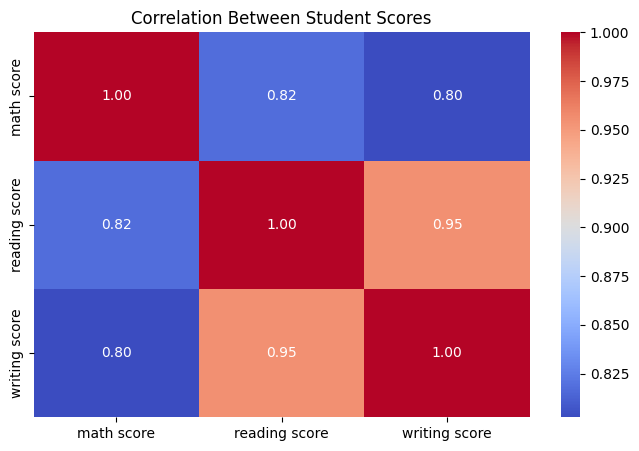

In [14]:

# Correlation Heatmap

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Between Student Scores")
plt.show()


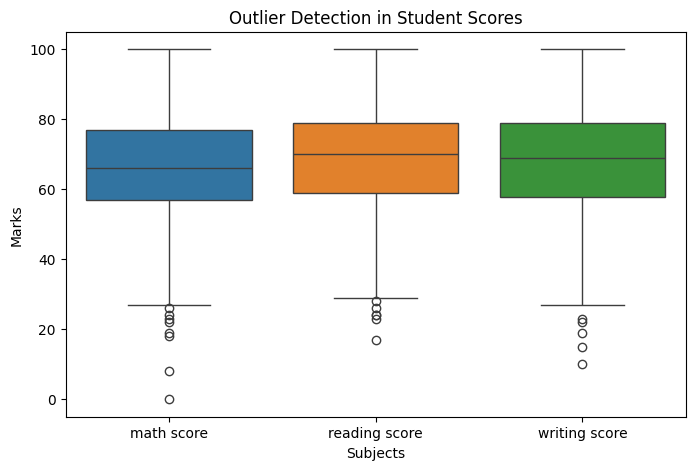

In [15]:

# Outlier Detection

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df[['math score', 'reading score', 'writing score']]
)

plt.title("Outlier Detection in Student Scores")
plt.xlabel("Subjects")
plt.ylabel("Marks")

plt.show()


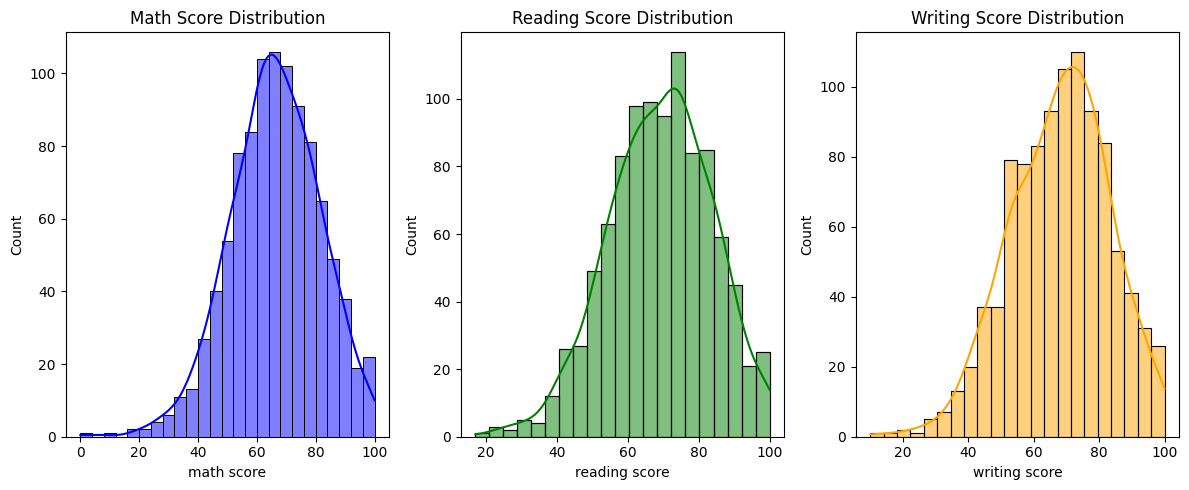

In [16]:

# Score Distribution

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
sns.histplot(df['math score'], kde=True, color='blue')
plt.title("Math Score Distribution")

plt.subplot(1, 3, 2)
sns.histplot(df['reading score'], kde=True, color='green')
plt.title("Reading Score Distribution")

plt.subplot(1, 3, 3)
sns.histplot(df['writing score'], kde=True, color='orange')
plt.title("Writing Score Distribution")

plt.tight_layout()
plt.show()


In [17]:

# Final Findings

print("========== FINAL FINDINGS ==========")

print("\nTotal Students:", len(df))

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nAverage Subject Scores:")
print(df[['math score', 'reading score', 'writing score']].mean().round(2))

print("\nGender-wise Performance:")
print(df.groupby('gender')[
    ['math score', 'reading score', 'writing score']
].mean().round(2))

print("\nCorrelation:")
print(correlation.round(2))

print("\n========== ANALYSIS COMPLETED ==========")


========== FINAL FINDINGS ==========

Total Students: 1000

Missing Values:
0

Duplicate Records:
0

Average Subject Scores:
math score       66.09
reading score    69.17
writing score    68.05
dtype: float64

Gender-wise Performance:
        math score  reading score  writing score
gender                                          
female       63.63          72.61          72.47
male         68.73          65.47          63.31

Correlation:
               math score  reading score  writing score
math score           1.00           0.82           0.80
reading score        0.82           1.00           0.95
writing score        0.80           0.95           1.00

========== ANALYSIS COMPLETED ==========


# Conclusion

Exploratory Data Analysis was performed on the Student Performance dataset using Python.

## Key Activities

1. Dataset exploration
2. Missing value detection
3. Duplicate record detection
4. Statistical analysis
5. Gender-wise performance comparison
6. Correlation analysis
7. Outlier detection

## Final Result

This project helped identify patterns and relationships between Mathematics, Reading and Writing scores.